* Introduction: Introduce the project, and your approach, talk about the process of how you came up with the metric and some alternatives you may have explored.


For this project we were tasked with picking the best neighborhood in Pittsburgh.

Because there are so many ways to define best, we decided that the first step was browsing through the Western Pennsylvania Regional Data Center. In order to avoid picking common metrics that had easy overlap, we each browsed at our own pace and found our own unique and distinct metrics. Our thought process was if we can unite three seperate components of Pittsburgh that are not commonly compared, we can accurately attribute what is the best neighborhood based on these metrics. The next step was finding an overarching theme to unite these metrics that would ultimately determine what is the best neighborhood. From there we gathered data, compared data, and created a system of uniting this data to find the best neighborhood.

Some alternatives we were thinking about that we did not explore were: best fire response in Pittsburgh and highest tourist activity in Pittsburgh. We were able to rule these overall comparisons out based on how they fit with the metrics we had chosen and what we really wanted to capture with the best neighborhood.


* The Metric: Describe your metric, and what features are you measuring. What datasets are you using?

We defined the best neighborhood in Pittsburgh as the neighborhood with the best public works. The datasets we chose were Pittsburgh water features, Pittsburgh fire incident reports, and Pittsburgh 311 service requests. We saw these three datasets as unique and distinct sets that could cover a large spread of Pittsburgh characterisitics. Additioanlly we thought public works suffices as an overall metric to define what neighborhood is best because public works is often associated with efficiency and resilience of a community.   


* The Best Neighborhood: Apply the metric from the previous section to determine the best neighborhood in Pittsburgh. Beyond just executing code, provide a narrative about why you think this is the best neighborhood. Incorporate a data visualization, perhaps to rank all of the neighborhoods or show a neighborhood’s best-ness over time. The key is to make a data driven argument.

In order to find the best public works in Pittsburgh we each ranked all of the neighborhoods from our respective datasets. From there, we compiled our rankings into a final ranking dictionary where each corresponding value to each neighborhood key is the sum of all rankings. Whichever neighborhood has the smallest corresponding value, or corresponding sum of ranks, is the best. If any neighborhood does not exist in one specific dataset's ranking then its value is assumed to be 100, which balances out since the largest dictionary is just under 100 items. 

This system finds the best neighborhood in Pittsburgh because it is dependent on all three datasets and it compensates for any neighborhoods not included in one of the datasets.



# Process for Ranking Water Features

Dictionary of Drinking Fountains in Pittsburgh Neighborhoods
{'Squirrel Hill South': 16, 'Highland Park': 12, 'Beechview': 10, 'Perry North': 10, 'Brookline': 8, 'Troy Hill': 8, 'Carrick': 8, 'Allegheny Center': 8, 'Elliott': 7, 'Brighton Heights': 6, 'Sheraden': 6, 'Mount Washington': 6, 'Terrace Village': 5, 'Manchester': 5, 'Crawford-Roberts': 5, 'Lincoln Place': 4, 'Shadyside': 4, 'Hazelwood': 4, 'Bloomfield': 4, 'Banksville': 3, 'Point Breeze': 3, 'Regent Square': 3, 'Morningside': 3, 'East Liberty': 3, 'South Side Flats': 3, 'Beltzhoover': 3, 'Central Business District': 3, 'Perry South': 3, 'Marshall-Shadeland': 3, 'Greenfield': 3, 'North Oakland': 3, 'Bedford Dwellings': 2, 'Allentown': 2, 'Crafton Heights': 2, 'West End': 2, 'Westwood': 2, 'Squirrel Hill North': 2, 'Stanton Heights': 2, 'Garfield': 2, 'Lincoln-Lemington-Belmar': 2, 'South Side Slopes': 2, 'Spring Garden': 2, 'Spring Hill-City View': 2, 'Duquesne Heights': 1, 'Oakwood': 1, 'Windgap': 1, 'East Hills': 1, 'Homewo

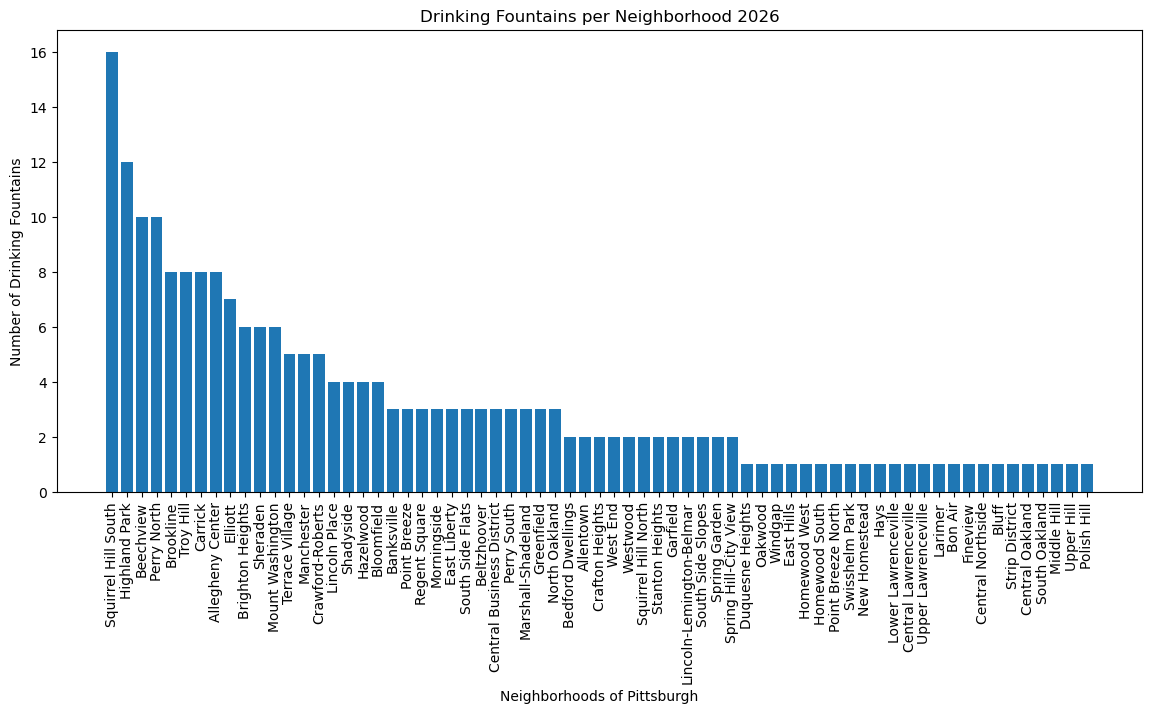


These are the rankings for the best overall water features for the neighborhoods

{'Squirrel Hill South': 1, 'Highland Park': 2, 'Beechview': 3, 'Perry North': 4, 'Brookline': 5, 'Troy Hill': 6, 'Carrick': 7, 'Allegheny Center': 8, 'Elliott': 9, 'Brighton Heights': 10, 'Sheraden': 11, 'Mount Washington': 12, 'Terrace Village': 13, 'Manchester': 14, 'Crawford-Roberts': 15, 'Lincoln Place': 16, 'Shadyside': 17, 'Hazelwood': 18, 'Bloomfield': 19, 'Banksville': 20, 'Point Breeze': 21, 'Regent Square': 22, 'Morningside': 23, 'East Liberty': 24, 'South Side Flats': 25, 'Beltzhoover': 26, 'Central Business District': 27, 'Perry South': 28, 'Marshall-Shadeland': 29, 'Greenfield': 30, 'North Oakland': 31, 'Bedford Dwellings': 32, 'Allentown': 33, 'Crafton Heights': 34, 'West End': 35, 'Westwood': 36, 'Squirrel Hill North': 37, 'Stanton Heights': 38, 'Garfield': 39, 'Lincoln-Lemington-Belmar': 40, 'South Side Slopes': 41, 'Spring Garden': 42, 'Spring Hill-City View': 43, 'Duquesne Heights': 44,

In [18]:
import pandas as pd
df = pd.read_csv("PittWaterFeatures.csv")
df.head()
import matplotlib.pyplot as plt
##create dictionary with neighborhoods and drinking fountain count
drinking_count = {}
for index, row in df.iterrows():
    n = row["neighborhood"]
    d = row["feature_type"]
    if(d == "Drinking Fountain" and n in drinking_count):
        drinking_count[n] += 1
    elif(d == "Drinking Fountain"):
        drinking_count[n] = 1
##sort the dictionary in descending order
sorted_drinking = dict(sorted(drinking_count.items(), key = lambda item: item[1], reverse = True))
##print out the dictionary
print("Dictionary of Drinking Fountains in Pittsburgh Neighborhoods")
print(sorted_drinking)
print()
##graph the dictionary on a table 
plt.figure(figsize = (14, 6))
plt.bar(sorted_drinking.keys(), sorted_drinking.values())
plt.xticks(rotation=90)
plt.xlabel("Neighborhoods of Pittsburgh")
plt.ylabel("Number of Drinking Fountains")
plt.title("Drinking Fountains per Neighborhood 2026")
plt.show()
print()
print("These are the rankings for the best overall water features for the neighborhoods")
print()
##create lists for the neighborhoods and list for the drinking fountain count
keys_list = list(sorted_drinking.keys())
values_list = list(sorted_drinking.values())
##create a new dictionary for the ranking based using neighborhoods and matching them with their index plus one in the sorted
##dictionary in descending order to give accurate ranking
ranking = {}
count = 1
for items in keys_list:
    ranking[items] = count
    count += 1
print(ranking)
##print reasoning of this metric used
print("This was decided based on number of Drinking Fountains per Neighborhood because Drinking Fountains made up 220 out of 288 total features")

# Process for Ranking Fire Incidents

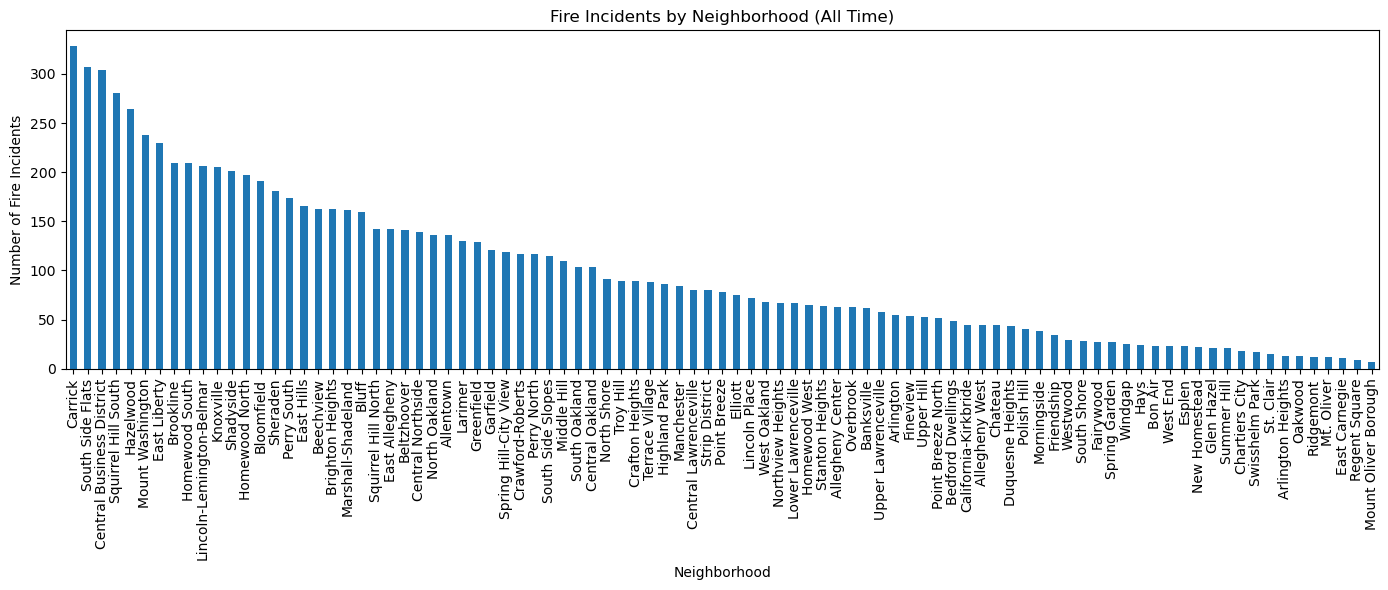

In [16]:
import pandas as pd
import matplotlib.pyplot as plt

# Load the data (it's tab-separated)
df = pd.read_csv("Fire-Incidents.tsv", sep="\t")

# Count how many incidents happened in each neighborhood
counts = df["neighborhood"].value_counts()

# Make the bar graph
counts.plot(kind="bar", figsize=(14, 6))
plt.title("Fire Incidents by Neighborhood (All Time)")
plt.xlabel("Neighborhood")
plt.ylabel("Number of Fire Incidents")
plt.tight_layout()
plt.show()

The graph above displays the frequency of reported fire incidents for every neighborhood in Pittsburgh of all the recorded data in the list. From the organization method used in earlier, the graph clearly indicates that the most fire-safe neighborhood in Pittsburgh is Mount Oliver Borough. 

Now we can create a ranked list of every neighborhood 

In [17]:
import pickle


counts = df["neighborhood"].value_counts()
counts = counts.iloc[::-1]
# rank = list(counts.index)
indexes = []
for i in range(len(counts)):
    indexes.append(i+1)
ranking = pd.DataFrame({'count':counts, 'rank':indexes})

# export data
with open("data.pkl", "wb") as file:
    pickle.dump(ranking, file)

ranking

,count,rank
neighborhood,,
Mount Oliver Borough,7,1
Regent Square,9,2
East Carnegie,11,3
Mt. Oliver,12,4
Ridgemont,12,5
...,...,...
Hazelwood,264,87
Squirrel Hill South,281,88
Central Business District,304,89


# Process for Ranking 311 Requests

In [22]:
import os
import urllib.request

FILE_311 = "311-data.csv"
URLS_311 = [
    "https://data.wprdc.org/datastore/dump/29462525-62a6-45bf-9b5e-ad2e1c06348d",
    "https://tools.wprdc.org/downstream/29462525-62a6-45bf-9b5e-ad2e1c06348d",
]

if not os.path.exists(FILE_311):
    for url in URLS_311:
        try:
            print(f"Downloading 311 data from {url}")
            urllib.request.urlretrieve(url, FILE_311)
            break
        except Exception as e:
            print(f"Failed: {e}")
    else:
        raise RuntimeError("Could not download the 311 data. Download it manually and save it as 311-data.csv.")

In [28]:
import pandas as pd
import matplotlib.pyplot as plt

# load dataset with only neighborhood, dates, and status code columns 
df = pd.read_csv("311-data.csv", usecols = ["neighborhood", "create_date_et", "closed_date_et", "status_code"])

# convert to datatime objects
df["create_date_et"] = pd.to_datetime(df["create_date_et"])
df["closed_date_et"] = pd.to_datetime(df["closed_date_et"])

# ensure numeric status codes
df["status_code"] = pd.to_numeric(df["status_code"], errors="coerce")

# clean data and copy into new independent dataframe
df["neighborhood"] = df["neighborhood"].replace(r"^\s*$", pd.NA, regex=True)
completed = df[(df["status_code"] == 1) & (df["neighborhood"].notna()) & (df["create_date_et"].notna()) & (df["closed_date_et"].notna())].copy()

# remaining rows after cleaning for reference
print("Original records:", len(df))
print("Remaining records:", len(completed))
print("Removed records:", len(df) - len(completed))

Original records: 815417
Remaining records: 689498
Removed records: 125919


In [27]:
# create new column, calculate completion times for requests, store in column
completed["completion_time"] = (completed["closed_date_et"] - completed["create_date_et"]).dt.total_seconds() / 86400

# group requests by neighborhood and calculate median completion time for each neighborhood
neighborhood_stats = completed.groupby("neighborhood")["completion_time"].agg(["median"])

# sort neighborhoods by median in ascending order
neighborhood_stats = neighborhood_stats.sort_values(by="median")

# assign ranks to neighborhoods based on median
neighborhood_stats["rank"] = range(1, len(neighborhood_stats) + 1)

# display neighborhoods with top 20 fastest completion times
neighborhood_stats.head(20)

,median,rank
neighborhood,,
Crafton Heights,2.055556,1
East Carnegie,4.882986,2
Ridgemont,4.943056,3
Stanton Heights,5.673611,4
Summer Hill,5.795833,5
Glen Hazel,5.935417,6
Westwood,6.150347,7
Chartiers City,6.486111,8
Bedford Dwellings,6.488194,9


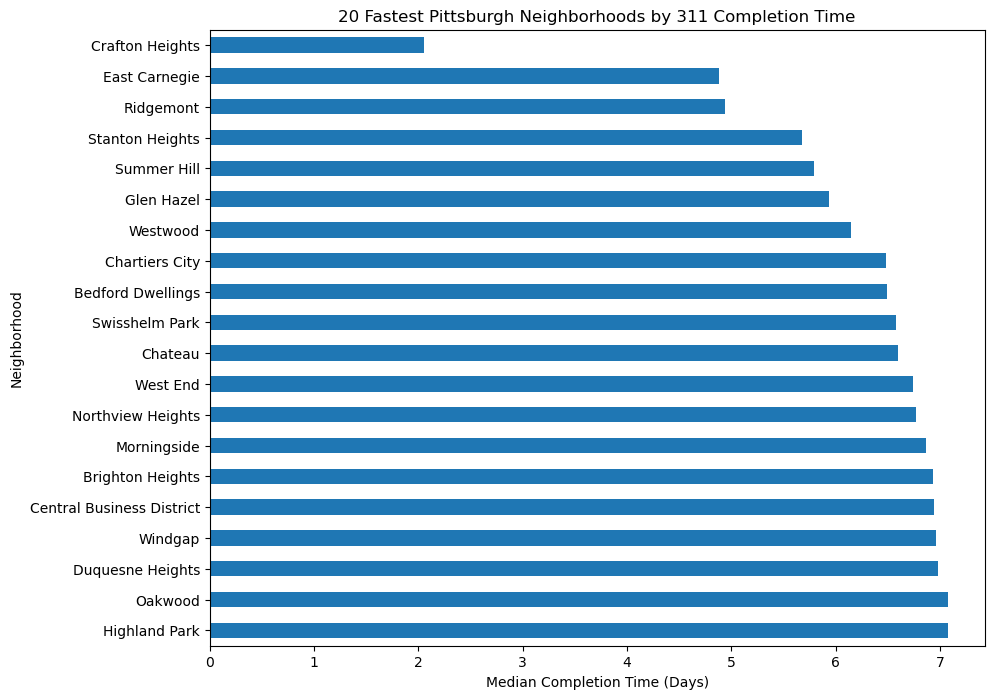

In [26]:
# data visualization

# create series for top 20 fastest request completion neighborhoods
top_20 = neighborhood_stats.head(20)

# create horizontal bar chart for top 20 neighborhoods, sort in ascending order
top_20["median"].sort_values().plot(kind="barh", figsize=(10, 8))
plt.gca().invert_yaxis()

# chart labels
plt.xlabel("Median Completion Time (Days)")
plt.ylabel("Neighborhood")
plt.title("20 Fastest Pittsburgh Neighborhoods by 311 Completion Time")

# display chart
plt.show()

# Process for Combining Ranks and Determining the Best Neighborhood

In [49]:
import pandas as pd
df = pd.read_csv("311_ranks.csv")
df.head()
import pickle





counts = df["neighborhood"].value_counts()
counts = counts.iloc[::-1]
# rank = list(counts.index)
indexes = []
for i in range(len(counts)):
    indexes.append(i+1)
ranking = pd.DataFrame({'count':counts, 'rank':indexes})

# export data
with open("data.pkl", "wb") as file:
    pickle.dump(ranking, file)

ranking
final_counts = {}

for key in sorted_drinking:
    if(key in final_counts):
        final_counts[key] += sorted_drinking[key]
    else:
        final_counts[key] = sorted_drinking[key]
        
for neighborhood, row in ranking.iterrows():
    n = neighborhood
    r = float(row["rank"])
    if(n in final_counts):
        final_counts[n] += r
    else:
        final_counts[n] = 100

for index, row in df.iterrows():
    n = row["neighborhood"]
    r = row["rank"]
    if(n in final_counts):
        final_counts[n] += r
    else:
        final_counts[n] = 100

sorted_final = dict(sorted(final_counts.items(), key = lambda item: item[1]))
print(sorted_final)


{'Duquesne Heights': 93.0, 'Oakwood': 93.0, 'Windgap': 93.0, 'East Hills': 93.0, 'Homewood West': 93.0, 'Homewood South': 93.0, 'Point Breeze North': 93.0, 'Swisshelm Park': 93.0, 'New Homestead': 93.0, 'Hays': 93.0, 'Lower Lawrenceville': 93.0, 'Central Lawrenceville': 93.0, 'Upper Lawrenceville': 93.0, 'Larimer': 93.0, 'Bon Air': 93.0, 'Fineview': 93.0, 'Central Northside': 93.0, 'Bluff': 93.0, 'Strip District': 93.0, 'Central Oakland': 93.0, 'South Oakland': 93.0, 'Middle Hill': 93.0, 'Upper Hill': 93.0, 'Polish Hill': 93.0, 'Bedford Dwellings': 94.0, 'Allentown': 94.0, 'Crafton Heights': 94.0, 'West End': 94.0, 'Westwood': 94.0, 'Squirrel Hill North': 94.0, 'Stanton Heights': 94.0, 'Garfield': 94.0, 'Lincoln-Lemington-Belmar': 94.0, 'South Side Slopes': 94.0, 'Spring Garden': 94.0, 'Spring Hill-City View': 94.0, 'Banksville': 95.0, 'Point Breeze': 95.0, 'Regent Square': 95.0, 'Morningside': 95.0, 'East Liberty': 95.0, 'South Side Flats': 95.0, 'Beltzhoover': 95.0, 'Central Business

* Conclusion: Reflect on how the data-driven determination of “best neighborhood” is the same or different from your personal favorite neighborhood. Each member of the group should write their own response to this.